# VN Gold Decision Support — Current Snapshot and Historical Evidence

This notebook presents the **latest saved model snapshot first**. It reads the data lake, forecast CSV and dashboard JSON produced by the pipeline. The stored walk-forward results are shown later as **historical reference evidence** because they used an earlier dataset and different model settings.

Run all cells from the repository root. The notebook does not collect data or retrain models when opened.

## Method and interpretation

- The target is net execution return: future SJC **buy** price divided by the current SJC **sell** price, minus one. This includes the quoted buy–sell spread.
- The forecast horizons are **1, 3 and 5 calendar months**. Each training label uses the first valid SJC quote on or after the anniversary date.
- The point forecast comes from Random Forest; Q10 is estimated with quantile Gradient Boosting. Q10 is an estimated 10th percentile, not a maximum possible loss.
- The estimated probability of positive return uses in-sample residual variation. It has not been calibrated out of sample for this snapshot configuration.
- Global market features are joined with a one-day cutoff. The premium uses a gold-futures proxy where an official benchmark is unavailable.

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Xác định thư mục dự án để notebook chạy được từ root hoặc thư mục notebooks/.
ROOT = Path.cwd()
if not (ROOT / "data" / "lake").exists():
    ROOT = ROOT.parent
assert (ROOT / "data" / "lake").exists(), "Run the notebook from the project root or notebooks/."

LAKE = ROOT / "data" / "lake"
MODELING = LAKE / "modeling"
WEB_DATA = ROOT / "web" / "data" / "gold_dashboard_data.json"

# Kiểm tra đủ artifact trước khi vẽ biểu đồ để báo lỗi rõ ràng khi pipeline chưa chạy.
required_files = [
    MODELING / "model_frame_daily.csv",
    MODELING / "snapshot_forecasts.csv",
    MODELING / "analysis_summary.json",
    MODELING / "model_results.csv",
    MODELING / "walk_forward_predictions.csv",
    MODELING / "decision_signals.csv",
    WEB_DATA,
]
missing_files = [str(path) for path in required_files if not path.exists()]
assert not missing_files, f"Missing required artifacts: {missing_files}"
print(f"Project: {ROOT}")

Project: C:\Users\Admin\Desktop\vn-gold-market-analysis


## 1. Current data and model snapshot

These files were refreshed independently of the older walk-forward evaluation. Always check the dates below before interpreting the charts or signal.

In [4]:
# Đọc khung đặc trưng và dự báo mới nhất; ép kiểu để tính phần trăm chính xác.
model_frame = pd.read_csv(MODELING / "model_frame_daily.csv", low_memory=False)
for column in ("date", "global_feature_date", "gpr_feature_date", "macro_feature_date"):
    if column in model_frame:
        model_frame[column] = pd.to_datetime(model_frame[column], errors="coerce")

snapshot = pd.read_csv(MODELING / "snapshot_forecasts.csv")
for column in ("predicted_net_return", "q10_predicted_net_return", "prob_return_positive"):
    snapshot[column] = pd.to_numeric(snapshot[column], errors="coerce")
snapshot["buy_signal"] = snapshot["buy_signal"].astype(str).str.lower().isin(("true", "1"))
dashboard = json.loads(WEB_DATA.read_text(encoding="utf-8"))

snapshot_date = str(snapshot["snapshot_date"].iloc[0])
latest_row = model_frame.sort_values("date").iloc[-1]
print(f"Model frame: {len(model_frame):,} observations, through {latest_row['date'].date()}")
print(f"Forecast snapshot: {snapshot_date}; dashboard end date: {dashboard['summary']['end_date']}")

Model frame: 5,570 observations, through 2026-10-20
Forecast snapshot: 2026-10-20; dashboard end date: 2026-10-20


In [5]:
# Ngày cuối của từng nhóm dữ liệu cho biết biến nào có thể đã cũ tại snapshot.
def latest_date(column):
    value = latest_row.get(column)
    return value.date().isoformat() if pd.notna(value) else "missing"

freshness = pd.DataFrame([
    {"component": "SJC model observation", "latest_date": latest_date("date")},
    {"component": "Global feature used (one-day lag)", "latest_date": latest_date("global_feature_date")},
    {"component": "Geopolitical risk feature", "latest_date": latest_date("gpr_feature_date")},
    {"component": "Vietnam macro feature", "latest_date": latest_date("macro_feature_date")},
    {"component": "Dashboard timeline", "latest_date": dashboard["summary"]["end_date"]},
])
display(freshness)
display(pd.DataFrame([{
    "sjc_buy_vnd_per_luong": latest_row["buy_price"],
    "sjc_sell_vnd_per_luong": latest_row["sell_price"],
    "spread_vnd_per_luong": latest_row["spread_abs"],
    "premium_proxy_vnd_per_luong": latest_row.get("premium"),
}]))

,component,latest_date
0,SJC model observation,2026-10-20
1,Global feature used (one-day lag),2026-10-19
2,Geopolitical risk feature,2026-10-19
3,Vietnam macro feature,2025-03-01
4,Dashboard timeline,2026-10-20


,sjc_buy_vnd_per_luong,sjc_sell_vnd_per_luong,spread_vnd_per_luong,premium_proxy_vnd_per_luong
0,139600000.0,142600000.0,3000000.0,-13507249.48


In [6]:
# Hiển thị tháng lịch và ngày đáo hạn để phân biệt với độ trễ theo số quan sát.
snapshot_view = snapshot.sort_values("horizon_months").assign(
    horizon_months=lambda d: d["horizon_months"].astype(int),
    net_return_pct=lambda d: (100 * d["predicted_net_return"]).round(2),
    q10_pct=lambda d: (100 * d["q10_predicted_net_return"]).round(2),
    estimated_positive_probability_pct=lambda d: (100 * d["prob_return_positive"]).round(1),
)[["horizon_months", "target_date", "net_return_pct", "q10_pct", "estimated_positive_probability_pct", "buy_signal"]]
display(snapshot_view)

,horizon_months,target_date,net_return_pct,q10_pct,estimated_positive_probability_pct,buy_signal
0,1,2026-11-20,-3.61,-5.72,4.6,False
1,3,2027-01-20,11.23,-7.92,100.0,True
2,5,2027-03-20,12.92,-18.73,100.0,False


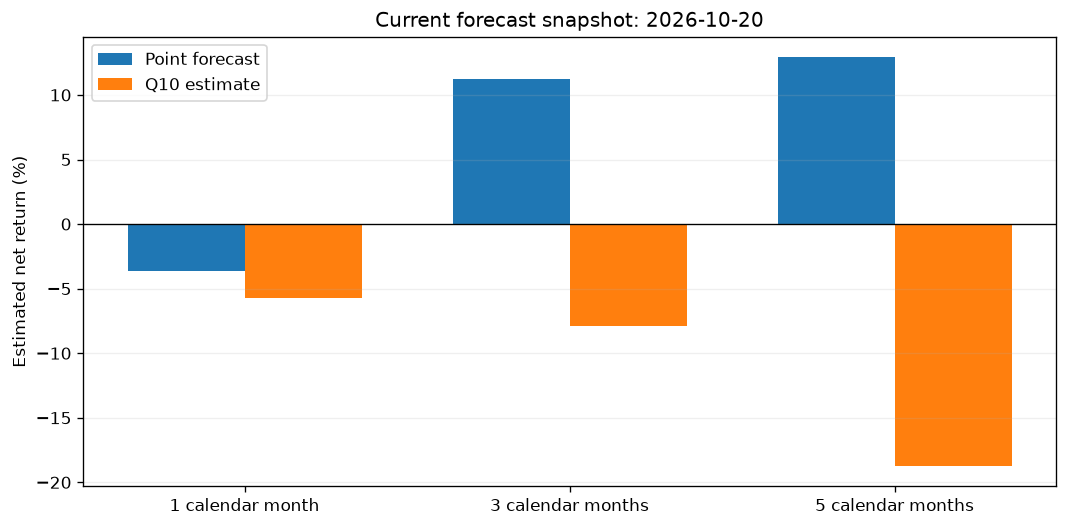

In [7]:
# Đặt dự báo điểm cạnh Q10 để người xem thấy mức rủi ro ước lượng của từng kỳ hạn.
plot_snapshot = snapshot.sort_values("horizon_months")
positions = np.arange(len(plot_snapshot))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(positions - 0.18, 100 * plot_snapshot["predicted_net_return"], width=0.36, label="Point forecast")
ax.bar(positions + 0.18, 100 * plot_snapshot["q10_predicted_net_return"], width=0.36, label="Q10 estimate")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(positions, [f"{int(h)} calendar {'month' if int(h) == 1 else 'months'}" for h in plot_snapshot["horizon_months"]])
ax.set_ylabel("Estimated net return (%)")
ax.set_title(f"Current forecast snapshot: {snapshot_date}")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
# Tạo kết luận từ CSV thay vì chép một khuyến nghị cố định vào notebook.
active_horizons = snapshot.loc[snapshot["buy_signal"], "horizon_months"].astype(int).tolist()
active_text = ", ".join(map(str, active_horizons)) if active_horizons else "none"
display(Markdown(
    f"**Snapshot {snapshot_date}:** buy signal at calendar-month horizons **{active_text}**. "
    "This is a model output, not a realized return. The historical leaderboard below "
    "does not validate this Random Forest / Q10 snapshot configuration."
))

**Snapshot 2026-10-20:** buy signal at calendar-month horizons **3**. This is a model output, not a realized return. The historical leaderboard below does not validate this Random Forest / Q10 snapshot configuration.

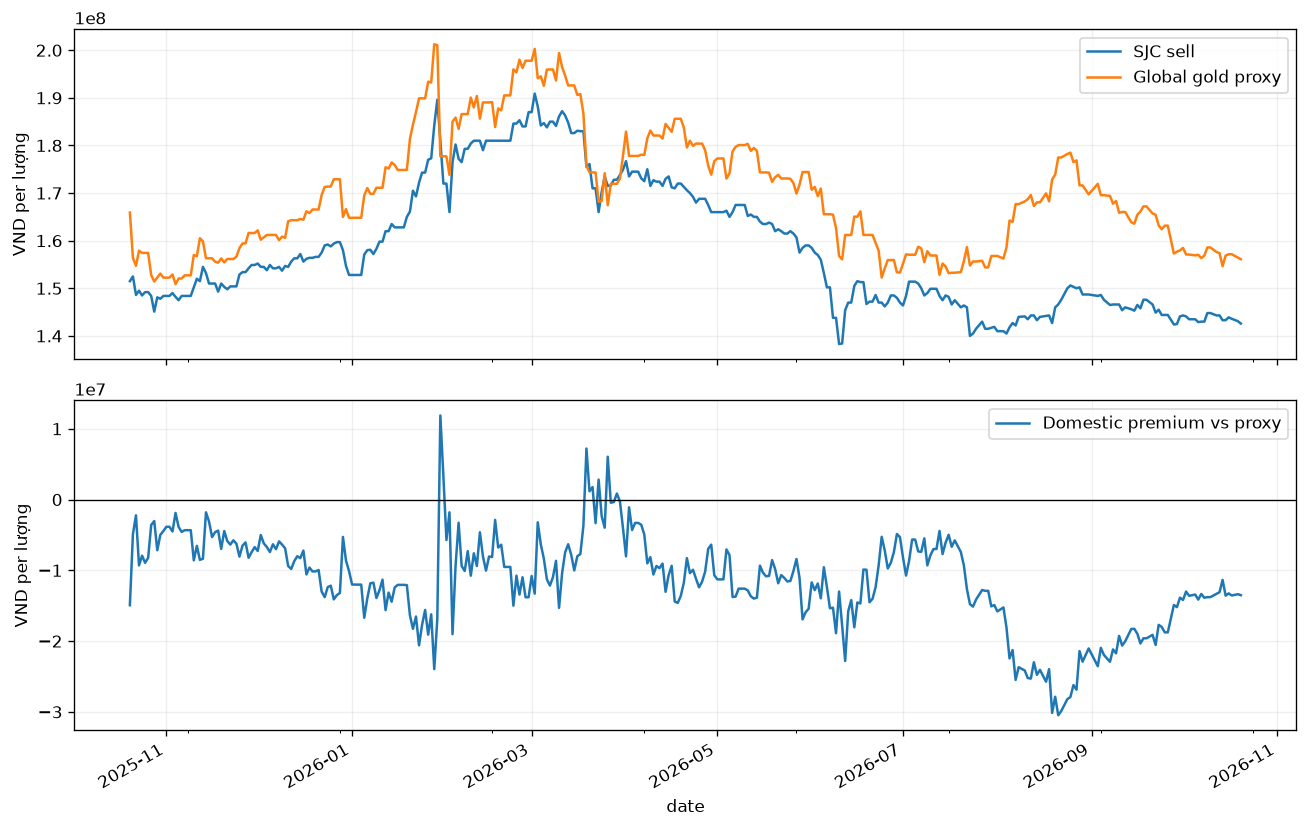

In [9]:
# So sánh một năm gần nhất để biểu đồ dài hạn không che mất diễn biến mới.
recent = model_frame.loc[model_frame["date"] >= latest_row["date"] - pd.Timedelta(days=365)].set_index("date")
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
recent["sell_price"].plot(ax=axes[0], label="SJC sell")
recent["global_gold_vnd_per_luong"].plot(ax=axes[0], label="Global gold proxy")
axes[0].set_ylabel("VND per lượng")
axes[0].legend()
recent["premium"].plot(ax=axes[1], label="Domestic premium vs proxy")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("VND per lượng")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [10]:
# Nhãn ở gần cuối chưa thể tính vì chưa có báo giá từ ngày tròn tháng trở đi.
target_summary = []
for horizon in (1, 3, 5):
    target = pd.to_numeric(model_frame[f"net_return_{horizon}m"], errors="coerce")
    target_summary.append({
        "horizon_months": horizon,
        "known_labels": int(target.notna().sum()),
        "missing_future_labels": int(target.isna().sum()),
        "historical_median_net_return_pct": round(100 * target.median(), 2),
    })
display(pd.DataFrame(target_summary))

,horizon_months,known_labels,missing_future_labels,historical_median_net_return_pct
0,1,5544,26,-0.63
1,3,5493,77,-0.22
2,5,5433,137,0.11


## 2. Stored walk-forward evaluation — historical reference

The files below are a separate walk-forward evaluation. Check its end date and horizon unit in the metadata table: older saved files use **21/63/105 observation shifts**, while the current snapshot uses **1/3/5 calendar months**. The evaluation also uses different model settings. **Do not present its MAE or signal rate as out-of-sample validation of the current snapshot**.

In [9]:
# Giữ metadata của lần backtest cũ tách biệt với khung dữ liệu và dự báo mới.
historical_summary = json.loads((MODELING / "analysis_summary.json").read_text(encoding="utf-8"))
results = pd.read_csv(MODELING / "model_results.csv")
predictions = pd.read_csv(MODELING / "walk_forward_predictions.csv", parse_dates=["date"])
signals = pd.read_csv(MODELING / "decision_signals.csv", parse_dates=["date"])
historical_horizon_col = "horizon_months" if "horizon_months" in results else "horizon_days"
historical_horizon_unit = "calendar months" if historical_horizon_col == "horizon_months" else "observation shifts"
display(pd.DataFrame([{
    "evaluation_end_date": historical_summary.get("date_max"),
    "horizon_unit": historical_horizon_unit,
    "evaluation_rows": historical_summary.get("rows"),
    "model_result_rows": len(results),
    "prediction_rows": len(predictions),
    "signal_rows": len(signals),
}]))

,evaluation_end_date,horizon_unit,evaluation_rows,model_result_rows,prediction_rows,signal_rows
0,2026-07-11,observation shifts,5485,186,57315,28242


In [10]:
# MAE thấp hơn là tốt hơn trong bảng mô hình dự báo điểm của lần backtest cũ.
leaderboard = (
    results.groupby(["model", historical_horizon_col], as_index=False)
    .agg(mae=("mae", "mean"), rmse=("rmse", "mean"),
         directional_accuracy=("directional_accuracy", "mean"), pinball_loss=("pinball_loss", "mean"))
    .sort_values([historical_horizon_col, "mae"], na_position="last")
)
display(leaderboard.groupby(historical_horizon_col, group_keys=False).head(5))

,model,horizon_days,mae,rmse,directional_accuracy,pinball_loss
30,sarimax_exog,21,0.023141,0.035122,0.563014,NaN
12,historical_median_return,21,0.032064,0.044944,0.590135,NaN
9,historical_mean_return,21,0.032254,0.045106,0.590135,NaN
21,naive_zero_return,21,0.032652,0.045398,0.015054,NaN
6,elastic_net,21,0.043450,0.055043,0.486820,NaN
22,naive_zero_return,63,0.071475,0.085109,0.012197,NaN
10,historical_mean_return,63,0.072617,0.086166,0.556806,NaN
13,historical_median_return,63,0.072846,0.086618,0.430997,NaN
7,elastic_net,63,0.094489,0.112510,0.453518,NaN
46,xgboost_mean,63,0.095403,0.109762,0.302029,NaN


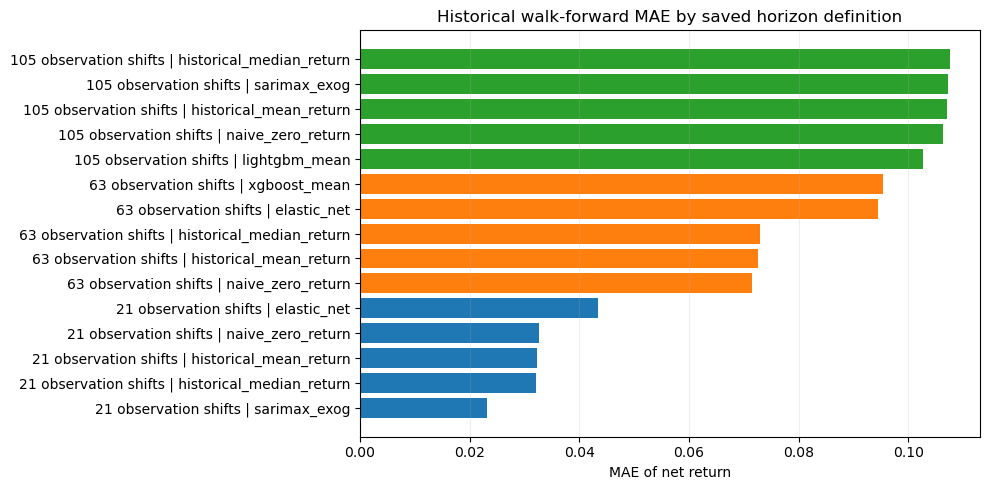

In [11]:
# Biểu đồ này thuộc lần backtest lịch sử, không đo chất lượng snapshot mới.
mean_models = leaderboard.dropna(subset=["mae"])
fig, ax = plt.subplots(figsize=(10, 5))
for horizon, group in mean_models.groupby(historical_horizon_col):
    best = group.nsmallest(5, "mae")
    ax.barh([f"{int(horizon)} {historical_horizon_unit} | {model}" for model in best["model"]], best["mae"])
ax.set_title("Historical walk-forward MAE by saved horizon definition")
ax.set_xlabel("MAE of net return")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Historical signal rule

The stored evaluation tested a grid of probability and Q10 thresholds. The chart below uses its saved default rule, `P(net return > 0) ≥ 0.50` and `Q10 ≥ −10%`. The current snapshot runner uses the same thresholds, but its model settings and data differ, so historical signal performance does not validate the current forecast.

In [12]:
# Chỉ thống kê quy tắc mặc định đã được lưu trong lần đánh giá lịch sử.
historical_signals = signals[
    np.isclose(signals["prob_threshold"], 0.50)
    & np.isclose(signals["q10_floor"], -0.10)
]
assert not historical_signals.empty, "The saved default signal rule has no rows."
decision_summary = (
    historical_signals.groupby([historical_horizon_col, "phase"], as_index=False)
    .agg(signal_days=("buy_signal", "sum"), observations=("buy_signal", "count"),
         avg_strategy_return=("strategy_return", "mean"),
         avg_realized_return=("actual_net_return", "mean"))
)
display(decision_summary)

,horizon_days,phase,signal_days,observations,avg_strategy_return,avg_realized_return
0,21,test,18,365,0.000494,0.019503
1,21,validation,0,365,0.000000,-0.005466
2,63,test,149,494,-0.014920,0.060635
3,63,validation,283,731,-0.002382,0.005063
4,105,test,449,452,0.127064,0.127626
5,105,validation,366,731,0.011855,0.027695


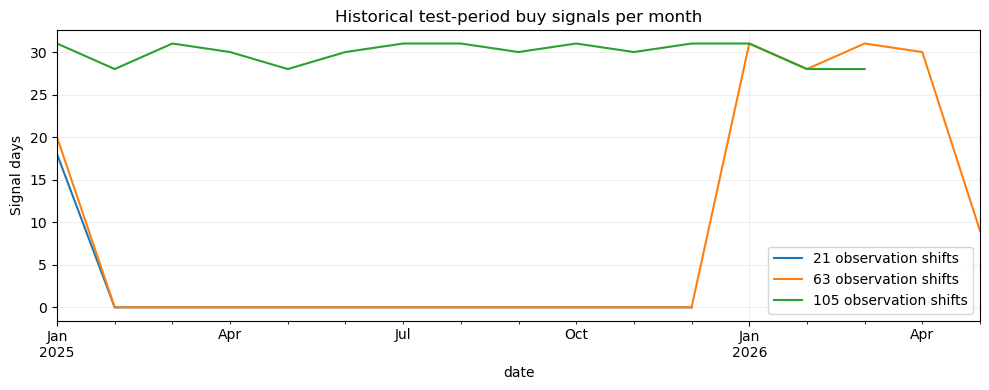

In [13]:
# Dùng tần suất cuối tháng rõ ràng để biểu đồ không sinh cảnh báo resample('M').
fig, ax = plt.subplots(figsize=(10, 4))
for horizon, group in historical_signals.loc[historical_signals["phase"].eq("test")].groupby(historical_horizon_col):
    monthly = group.set_index("date")["buy_signal"].resample("ME").sum()
    monthly.plot(ax=ax, label=f"{int(horizon)} {historical_horizon_unit}")
ax.set_title("Historical test-period buy signals per month")
ax.set_ylabel("Signal days")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Limitations and next checks

- The current snapshot lacks a walk-forward test with the same feature-selection and model settings. The stored July evaluation remains historical evidence only.
- Probability estimates use training residuals and need out-of-sample calibration. Q10 is an estimated percentile, not a guaranteed loss bound.
- The official Caldara–Iacoviello daily GPR source is current through 2026-10-19 in this run; Vietnam macro data still lag the SJC quote. Inspect the freshness table above. The gold reference used for premium is usually a futures proxy.
- New RSS headlines have publication dates and URLs, but were collected on 2026-10-21; headline-derived events are proxies, not verified official SBV decisions.
- The current targets and paper-trading ledger use calendar months and the first valid quote on or after the anniversary. The stored historical backtest still uses observation shifts.
- Run a matched walk-forward evaluation on the new calendar-month labels before using signal performance as decision evidence.

In [14]:
# Chặn notebook kết thúc thành công nếu ba artifact chính không cùng ngày snapshot.
assert snapshot["snapshot_date"].nunique() == 1
assert snapshot_date == latest_row["date"].date().isoformat()
assert snapshot_date == dashboard["summary"]["end_date"]
assert snapshot_date == dashboard["recommendations"]["snapshot_date"]
assert snapshot.sort_values("horizon_months")["buy_signal"].tolist() == [
    bool(row["buy_signal"]) for row in dashboard["recommendations"]["horizons"]
]
assert snapshot["horizon_months"].tolist() == [1, 3, 5]
assert all(
    pd.Timestamp(row["target_date"]) == pd.Timestamp(snapshot_date) + pd.DateOffset(months=int(row["horizon_months"]))
    for _, row in snapshot.iterrows()
)
assert (model_frame["global_feature_date"].dropna() <= model_frame.loc[model_frame["global_feature_date"].notna(), "date"]).all()
assert (model_frame["gpr_feature_date"].dropna() <= model_frame.loc[model_frame["gpr_feature_date"].notna(), "date"]).all()
print("Current snapshot, dashboard and as-of checks passed.")

Current snapshot, dashboard and as-of checks passed.
